In [1]:
import cv2
import os
import random
import gc
import pywt

In [2]:
import numpy as np
import scipy.io as sio
import scipy.misc as misc
import tensorflow as tf
import matplotlib.pyplot as plt
%matplotlib inline

C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.3 when it was built against 1.14.2, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


In [3]:
from keras import backend as K
from keras.layers import Add, Activation, BatchNormalization
from keras.layers import Concatenate, Conv2D, Input, Layer
from keras.models import Model
from keras.optimizers import Adam
from keras.callbacks import LearningRateScheduler, ModelCheckpoint

from scipy import ndimage
from scipy import signal
from scipy.ndimage import zoom
from scipy.ndimage import correlate
from scipy.special import erfinv

from sklearn.decomposition import PCA as princomp
from skimage.transform import resize

from cv2.ximgproc import guidedFilter

from tqdm import tqdm

from PIL import Image

In [4]:
'''loading data'''
original_msi = np.load("D:/geoinformatics/MajorProject/main/npyfiles/rgb_npy/WG_RGB_BLOCK_0_9.npy")
original_msi = np.transpose(original_msi, (1, 2, 0))
original_pan = np.load("D:/geoinformatics/MajorProject/main/npyfiles/pan_npy/WG_PAN_BLOCK_0_9.npy")
original_pan = np.transpose(original_pan, (1, 2, 0))

In [5]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & uint16
(1024, 1024, 1) & uint16


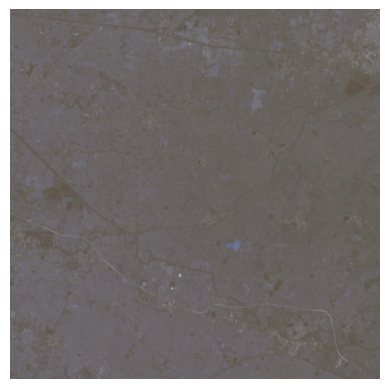

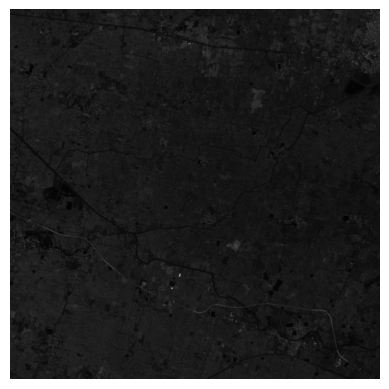

In [6]:
# Extract the RGB channels
rgb_image = original_msi[..., :3]

# Since the image is in uint16 format, we need to normalize it for display
# Normalize to range [0, 1] for matplotlib
rgb_image = rgb_image.astype(np.float32) / np.max(rgb_image)

# Display the RGB image
plt.imshow(rgb_image)
plt.axis('off')  # Hide the axes
plt.show()

plt.axis("off")
plt.imshow(original_pan, cmap= 'gray')

In [7]:
'''normalization'''
max_patch, min_patch = np.max(original_msi, axis=(0,1)), np.min(original_msi, axis=(0,1))
original_msi = np.float32(original_msi-min_patch) / (max_patch - min_patch)

max_patch, min_patch = np.max(original_pan, axis=(0,1)), np.min(original_pan, axis=(0,1))
original_pan = np.float32(original_pan-min_patch) / (max_patch - min_patch)

In [8]:
print(original_msi.shape , "&", original_msi.dtype)
print(original_pan.shape , "&", original_pan.dtype)

(512, 512, 4) & float32
(1024, 1024, 1) & float32


In [9]:
gt = np.uint8(np.resize(original_msi, (1024, 1024, 4)))

In [10]:
print(gt.shape , "&", gt.dtype)

(1024, 1024, 4) & uint8


In [11]:
print('ms shape: ', original_msi.shape, 'pan shape: ', original_pan.shape)

'''setting save parameters'''
save_images = True

save_dir= "D:/geoinformatics/MajorProject/main/output_tif/0_9/"
if save_images and (not os.path.isdir(save_dir)):
    os.makedirs(save_dir)

ms shape:  (512, 512, 4) pan shape:  (1024, 1024, 1)


In [12]:
def upsample_bicubic(image, ratio):
    h,w,c = image.shape
    re_image = cv2.resize(image, (w*ratio, h*ratio), interpolation=cv2.INTER_CUBIC)
    
    return re_image

In [13]:
def upsample_interp23(image, ratio):

    image = np.transpose(image, (2, 0, 1))
    
    b,r,c = image.shape

    CDF23 = 2*np.array([0.5, 0.305334091185, 0, -0.072698593239, 0, 0.021809577942, 0, -0.005192756653, 0, 0.000807762146, 0, -0.000060081482])
    d = CDF23[::-1] 
    CDF23 = np.insert(CDF23, 0, d[:-1])
    BaseCoeff = CDF23
    
    first = 1
    for z in range(1,int(np.log2(ratio))+1):
        I1LRU = np.zeros((b, 2**z*r, 2**z*c))
        if first:
            I1LRU[:, 1:I1LRU.shape[1]:2, 1:I1LRU.shape[2]:2]=image
            first = 0
        else:
            I1LRU[:,0:I1LRU.shape[1]:2,0:I1LRU.shape[2]:2]=image
        
        for ii in range(0,b):
            t = I1LRU[ii,:,:]
            for j in range(0,t.shape[0]):
                t[j,:]=ndimage.correlate(t[j,:],BaseCoeff,mode='wrap')
            for k in range(0,t.shape[1]):
                t[:,k]=ndimage.correlate(t[:,k],BaseCoeff,mode='wrap')
            I1LRU[ii,:,:]=t
        image = I1LRU
        
    re_image=np.transpose(I1LRU, (1, 2, 0))
        
    return re_image

In [14]:
def resize_image(image, ratio, interpolation=Image.BICUBIC):
    """
    Resize an image using Pillow.
    """
    pil_image = Image.fromarray(image)
    new_size = (int(image.shape[1] / ratio), int(image.shape[0] / ratio))
    resized_image = pil_image.resize(new_size, interpolation)
    return np.array(resized_image, dtype=np.float64)

In [15]:
def downgrade_images(I_MS, I_PAN, ratio, sensor='landsat8'):
    """
    Downgrade MS and PAN by a ratio factor with given sensor's gains.
    """
    I_MS = np.double(I_MS)
    I_PAN = np.double(I_PAN)
    
    I_MS = np.transpose(I_MS, (2, 0, 1))
    I_PAN = np.squeeze(I_PAN)
    
    ratio = np.double(ratio)
    flag_PAN_MTF = 0
    
    if sensor == 'landsat8':
        flag_resize_new = 2
        GNyq = np.asarray([0.29, 0.26, 0.26, 0.25], dtype='float32')  # Band Order: B, G, R, NIR
        GNyqPan = 0.23
    else:
        '''the default way'''
        flag_resize_new = 1
    
    '''the default downgrading method is gaussian'''
    if flag_resize_new == 1:
        sig = (1 / (2 * (2.772587) / ratio**2))**0.5
        kernel = np.multiply(cv2.getGaussianKernel(9, sig), cv2.getGaussianKernel(9, sig).T)
        
        t = []
        for i in range(I_MS.shape[0]):
            temp = signal.convolve2d(I_MS[i, :, :], kernel, mode='same', boundary='wrap')
            temp = temp[0::int(ratio), 0::int(ratio)]
            temp = np.expand_dims(temp, 0)
            t.append(temp)
            
        I_MS_LR = np.concatenate(t, axis=0)
        
        I_PAN_LR = signal.convolve2d(I_PAN, kernel, mode='same', boundary='wrap')
        I_PAN_LR = I_PAN_LR[0::int(ratio), 0::int(ratio)]
        
    elif flag_resize_new == 2:
        N = 41
        I_MS_LP = np.zeros(I_MS.shape)
        fcut = 1 / ratio
        
        for j in range(I_MS.shape[0]):
            # FIR filter with window method
            alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyq[j])))
            H = gaussian2d(N, alpha)
            Hd = H / np.max(H)
            w = kaiser2d(N, 0.5)
            h = fir_filter_wind(Hd, w)
            I_MS_LP[j, :, :] = ndimage.correlate(I_MS[j, :, :], np.real(h), mode='nearest')
        
        if flag_PAN_MTF == 1:
            # FIR filter with window method
            alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyqPan)))
            H = gaussian2d(N, alpha)
            Hd = H / np.max(H)
            h = fir_filter_wind(Hd, w)
            I_PAN = ndimage.correlate(I_PAN, np.real(h), mode='nearest')
            I_PAN_LR = I_PAN[int(ratio / 2):-1:int(ratio), int(ratio / 2):-1:int(ratio)]
        else:
            # Bicubic resize using PIL
            I_PAN_pad = np.pad(I_PAN, int(2 * ratio), 'symmetric')
            I_PAN_LR = resize_image(I_PAN_pad, ratio)
            I_PAN_LR = I_PAN_LR[2:-2, 2:-2]
            
        I_MS_LR = I_MS_LP[:, int(ratio / 2):-1:int(ratio), int(ratio / 2):-1:int(ratio)]     
    
    I_MS_LR = np.transpose(I_MS_LR, (1, 2, 0))
    I_PAN_LR = np.expand_dims(I_PAN_LR, -1)
    
    return I_MS_LR, I_PAN_LR

In [16]:
def sam(img1, img2):
    """SAM for 3D image, shape (H, W, C); uint or float[0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    
    if img1.ndim != 3 or img1.shape[2] <= 1:
        raise ValueError('Images must be 3D with more than 1 channel.')

    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)

    inner_product = np.sum(img1_ * img2_, axis=2)
    img1_spectral_norm = np.sqrt(np.sum(img1_**2, axis=2))
    img2_spectral_norm = np.sqrt(np.sum(img2_**2, axis=2))

    # Avoid division by zero
    norm_product = img1_spectral_norm * img2_spectral_norm
    norm_product = np.where(norm_product == 0, np.finfo(np.float64).eps, norm_product)

    cos_theta = np.clip(inner_product / norm_product, -1.0, 1.0)
    
    return np.mean(np.arccos(cos_theta))

In [17]:
def psnr(img1, img2, dynamic_range=255):
    """PSNR metric, img uint8 if 225; uint16 if 2047"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    mse = np.mean((img1_ - img2_)**2)
    if mse <= 1e-10:
        return np.inf
    return 20 * np.log10(dynamic_range / (np.sqrt(mse) + np.finfo(np.float64).eps))

In [18]:
def scc(img1, img2):
    """SCC for 2D (H, W)or 3D (H, W, C) image; uint or float[0, 1]"""
    if not  img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    if img1_.ndim == 2:
        return np.corrcoef(img1_.reshape(1, -1), img2_.rehshape(1, -1))[0, 1]
    elif img1_.ndim == 3:
        #print(img1_[..., i].reshape[1, -1].shape)
        #test = np.corrcoef(img1_[..., i].reshape[1, -1], img2_[..., i].rehshape(1, -1))
        #print(type(test))
        ccs = [np.corrcoef(img1_[..., i].reshape(1, -1), img2_[..., i].reshape(1, -1))[0, 1]
               for i in range(img1_.shape[2])]
        return np.mean(ccs)
    else:
        raise ValueError('Wrong input image dimensions.')

In [19]:
def _qindex(img1, img2, block_size=2):
    """Q-index for 2D (one-band) image, shape (H, W); uint or float [0, 1]"""
    assert block_size > 1, 'block_size shold be greater than 1!'
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    window = np.ones((block_size, block_size)) / (block_size**2)
    # window_size = block_size**2
    # filter, valid
    pad_topleft = int(np.floor(block_size/2))
    pad_bottomright = block_size - 1 - pad_topleft
    mu1 = cv2.filter2D(img1_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu2 = cv2.filter2D(img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu2_sq
#    print(mu1_mu2.shape)
    #print(sigma2_sq.shape)
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[pad_topleft:-pad_bottomright, pad_topleft:-pad_bottomright] - mu1_mu2

    # all = 1, include the case of simga == mu == 0
    qindex_map = np.ones(sigma12.shape)
    # sigma == 0 and mu != 0
    
#    print(np.min(sigma1_sq + sigma2_sq), np.min(mu1_sq + mu2_sq))
    
    idx = ((sigma1_sq + sigma2_sq) < 1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] = 2 * mu1_mu2[idx] / (mu1_sq + mu2_sq)[idx]
    # sigma !=0 and mu == 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) < 1e-8)
    qindex_map[idx] = 2 * sigma12[idx] / (sigma1_sq + sigma2_sq)[idx]
    # sigma != 0 and mu != 0
    idx = ((sigma1_sq + sigma2_sq) >1e-8) * ((mu1_sq + mu2_sq) >1e-8)
    qindex_map[idx] =((2 * mu1_mu2[idx]) * (2 * sigma12[idx])) / (
        (mu1_sq + mu2_sq)[idx] * (sigma1_sq + sigma2_sq)[idx])
    
    return np.mean(qindex_map)

In [20]:
def qindex(img1, img2, block_size=2):
    """Q-index for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1]"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _qindex(img1, img2, block_size)
    elif img1.ndim == 3:
        qindexs = [_qindex(img1[..., i], img2[..., i], block_size) for i in range(img1.shape[2])]
        return np.array(qindexs).mean()
    else:
        raise ValueError('Wrong input image dimensions.')

In [21]:
def _ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (one-band) image, shape (H, W); uint8 if 225; uint16 if 2047"""
    C1 = (0.01 * dynamic_range)**2
    C2 = (0.03 * dynamic_range)**2
    
    img1_ = img1.astype(np.float64)
    img2_ = img2.astype(np.float64)
    kernel = cv2.getGaussianKernel(11, 1.5)  # kernel size 11
    window = np.outer(kernel, kernel.transpose())
    
    mu1 = cv2.filter2D(img1_, -1, window)[5:-5, 5:-5]  # valid
    mu2 = cv2.filter2D(img2_, -1, window)[5:-5, 5:-5]
    mu1_sq = mu1**2
    mu2_sq = mu2**2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = cv2.filter2D(img1_**2, -1, window)[5:-5, 5:-5] - mu1_sq
    sigma2_sq = cv2.filter2D(img2_**2, -1, window)[5:-5, 5:-5] - mu2_sq
    sigma12 = cv2.filter2D(img1_ * img2_, -1, window)[5:-5, 5:-5] - mu1_mu2
    
    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / (
        (mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim_map.mean()

In [22]:
def ssim(img1, img2, dynamic_range=255):
    """SSIM for 2D (H, W) or 3D (H, W, C) image; uint8 if 225; uint16 if 2047"""
    if not img1.shape == img2.shape:
        raise ValueError('Input images must have the same dimensions.')
    if img1.ndim == 2:
        return _ssim(img1, img2, dynamic_range)
    elif img1.ndim == 3:
        ssims = [_ssim(img1[..., i], img2[..., i], dynamic_range) for i in range(img1.shape[2])]
        return np.array(ssims).mean()
    else:
        raise ValueError('Wrong input image dimensions.')


In [23]:
def ergas(img_fake, img_real, scale=2):
    """ERGAS for 2D (H, W) or 3D (H, W, C) image; uint or float [0, 1].
    scale = spatial resolution of PAN / spatial resolution of MUL, default 4."""
    if not img_fake.shape == img_real.shape:
        raise ValueError('Input images must have the same dimensions.')
    img_fake_ = img_fake.astype(np.float64)
    img_real_ = img_real.astype(np.float64)
    if img_fake_.ndim == 2:
        mean_real = img_real_.mean()
        mse = np.mean((img_fake_ - img_real_)**2)
        return 100 / scale * np.sqrt(mse / (mean_real**2 + np.finfo(np.float64).eps))
    elif img_fake_.ndim == 3:
        means_real = img_real_.reshape(-1, img_real_.shape[2]).mean(axis=0)
        mses = ((img_fake_ - img_real_)**2).reshape(-1, img_fake_.shape[2]).mean(axis=0)
        return 100 / scale * np.sqrt((mses / (means_real**2 + np.finfo(np.float64).eps)).mean())
    else:
        raise ValueError('Wrong input image dimensions.')

In [24]:
####################
# observation model
####################

In [25]:
def gaussian2d(N, std):
    
    t=np.arange(-(N-1)/2,(N+2)/2)
    t1,t2=np.meshgrid(t,t)
    std=np.double(std)
    w = np.exp(-0.5*(t1/std)**2)*np.exp(-0.5*(t2/std)**2) 
    return w

In [26]:
def kaiser2d(N, beta):
    
    t=np.arange(-(N-1)/2,(N+1)/2)/np.double(N-1)
    t1,t2=np.meshgrid(t,t)
    t12=np.sqrt(t1*t1+t2*t2)
    w1=np.kaiser(N,beta)
    w=np.interp(t12,t,w1)
    w[t12>t[-1]]=0
    w[t12<t[0]]=0
    
    return w

In [27]:
def resize_window(w, target_shape):
    """
    Resize the window function to match the target shape.
    """
    factors = (target_shape[0] / w.shape[0], target_shape[1] / w.shape[1])
    resized_w = zoom(w, factors, mode='constant')
    return resized_w

In [28]:
def fir_filter_wind(Hd, w):
    """
    compute fir (finite impulse response) filter with window method
    Hd: desired freqeuncy response (2D)
    w: window (2D)
    """
    hd = np.rot90(np.fft.fftshift(np.rot90(Hd, 2)), 2)
    h = np.fft.fftshift(np.fft.ifft2(hd))
    h = np.rot90(h, 2)

    if h.shape != w.shape:
        w = resize_window(w, h.shape)
        print(f"Shape of w after resizing: {w.shape}")
    h = h * w
    h = h / np.sum(h)
    return h

In [29]:
def GNyq2win(GNyq, scale=2, N=41):
    """Generate a 2D convolutional window from a given GNyq
    GNyq: Nyquist frequency
    scale: spatial size of PAN / spatial size of MS
    """
    #fir filter with window method
    fcut = 1 / scale
    alpha = np.sqrt(((N - 1) * (fcut / 2))**2 / (-2 * np.log(GNyq)))
    H = gaussian2d(N, alpha)
    Hd = H / np.max(H)
    w = kaiser2d(N, 0.5)
    h = fir_filter_wind(Hd, w)
    return np.real(h)

In [30]:
def mtf_resize(img, satellite='landsat8', scale=2):
    # satellite GNyq
    scale = int(scale)
    if satellite == 'landsat8':
        GNyq = [0.29, 0.26, 0.26,0.25]  # Band Order: B,G,R,NIR
        GNyqPan = 0.23
    else:
        raise NotImplementedError('satellite: landsat 8')
    # lowpass
    img_ = img.squeeze()
    img_ = img_.astype(np.float64)
    if img_.ndim == 2:  # Pan
        H, W = img_.shape
        lowpass = GNyq2win(GNyqPan, scale = 2, N=41)
    elif img_.ndim == 3:  # MS
        H, W, _ = img.shape
        lowpass = [GNyq2win(gnyq, scale = 2, N=41) for gnyq in GNyq]
        lowpass = np.stack(lowpass, axis=-1)
    img_ = correlate(img_, lowpass, mode='nearest')
    # downsampling
    output_size = (H // scale, W // scale)
    img_ = cv2.resize(img_, dsize=output_size, interpolation=cv2.INTER_NEAREST)
    return img_

In [31]:
##################
# No reference IQA
##################

In [32]:
def D_lambda(img_fake, img_lm, block_size=32, p=1):
    """Spectral distortion
    img_fake, generated HRMS
    img_lm, LRMS"""
    assert img_fake.ndim == img_lm.ndim == 3, 'Images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # D_lambda
    Q_fake = []
    Q_lm = []
    for i in range(C_f):
        for j in range(i+1, C_f):
            # for fake
            band1 = img_fake[..., i]
            band2 = img_fake[..., j]
            Q_fake.append(_qindex(band1, band2, block_size=block_size))
            # for real
            band1 = img_lm[..., i]
            band2 = img_lm[..., j]
            Q_lm.append(_qindex(band1, band2, block_size=block_size))
    Q_fake = np.array(Q_fake)
    Q_lm = np.array(Q_lm)
    D_lambda_index = (np.abs(Q_fake - Q_lm) ** p).mean()
    return D_lambda_index ** (1/p)

In [33]:
def D_s(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, q=1):
    """Spatial distortion
    img_fake, generated HRMS
    img_lm, LRMS
    pan, HRPan"""
    # fake and lm
    assert img_fake.ndim == img_lm.ndim == 3, 'MS images must be 3D!'
    H_f, W_f, C_f = img_fake.shape
    H_r, W_r, C_r = img_lm.shape
    print(f"H_f: {H_f}, W_f: {W_f}, H_r: {H_r}, W_r: {W_r}, scale: {scale}")
    assert H_f // H_r == W_f // W_r == scale, 'Spatial resolution should be compatible with scale'
    assert C_f == C_r, 'Fake and lm should have the same number of bands!'
    # fake and pan
    assert pan.ndim == 3, 'Panchromatic image must be 3D!'
    H_p, W_p, C_p = pan.shape
    assert C_p == 1, 'size of 3rd dim of Panchromatic image must be 1'
    assert H_f == H_p and W_f == W_p, "Pan's and fake's spatial resolution should be the same"
    # get LRPan, 2D
    pan_lr = mtf_resize(pan, satellite=satellite, scale=scale)
    #print(pan_lr.shape)
    # D_s
    Q_hr = []
    Q_lr = []
    for i in range(C_f):
        # for HR fake
        band1 = img_fake[..., i]
        band2 = pan[..., 0] # the input PAN is 3D with size=1 along 3rd dim
        #print(band1.shape)
        #print(band2.shape)
        Q_hr.append(_qindex(band1, band2, block_size=block_size))
        band1 = img_lm[..., i]
        band2 = pan_lr  # this is 2D
        #print(band1.shape)
        #print(band2.shape)
        Q_lr.append(_qindex(band1, band2, block_size=block_size))
    Q_hr = np.array(Q_hr)
    Q_lr = np.array(Q_lr)
    D_s_index = (np.abs(Q_hr - Q_lr) ** q).mean()
    return D_s_index ** (1/q)

In [34]:
def qnr(img_fake, img_lm, pan, satellite='landsat8', scale=2, block_size=32, p=1, q=1, alpha=1, beta=1):
    """QNR - No reference IQA"""
    D_lambda_idx = D_lambda(img_fake, img_lm, block_size, p)
    D_s_idx = D_s(img_fake, img_lm, pan, satellite, scale, block_size, q)
    QNR_idx = (1 - D_lambda_idx) ** alpha * (1 - D_s_idx) ** beta
    return QNR_idx

In [35]:
def ref_evaluate(pred, gt):
    #reference metrics
    c_psnr = psnr(pred, gt)
    c_ssim = ssim(pred, gt)
    c_sam = sam(pred, gt)
    c_ergas = ergas(pred, gt)
    c_scc = scc(pred, gt)
    c_q = qindex(pred, gt)

    return [c_psnr, c_ssim, c_sam, c_ergas, c_scc, c_q]

In [36]:
def no_ref_evaluate(pred, pan, hs):
    #no reference metrics
    c_D_lambda = D_lambda(pred, hs)
    c_D_s = D_s(pred, hs, pan)
    c_qnr = qnr(pred, hs, pan)
    
    return [c_D_lambda, c_D_s, c_qnr]

In [37]:
'''evaluating all methods'''
ref_results={}
ref_results.update({'metrics: ':'  PSNR,     SSIM,   SAM,    ERGAS,  SCC,    Q'})
no_ref_results={}
no_ref_results.update({'metrics: ':'  D_lamda, D_s,    QNR'})

In [38]:
def Bicubic(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    # jsut upsample with bicubic
    I_Bicubic = upsample_bicubic(hs, ratio)
    
    #adjustment
    I_Bicubic[I_Bicubic<0]=0
    I_Bicubic[I_Bicubic>1]=1
    
    return np.uint8(I_Bicubic*255)

In [39]:
'''Bicubic method'''
print('evaluating Bicubic method')
fused_image = Bicubic(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
print("gt:", gt.shape, "&", gt.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'Bicubic    ':temp_ref_results})
no_ref_results.update({'Bicubic    ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'Bicubic.tiff', fused_image[:, :, :])

evaluating Bicubic method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
gt: (1024, 1024, 4) & uint8


C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [40]:
def Brovey(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    I = np.mean(u_hs, axis=-1)
    
    image_hr = (pan-np.mean(pan))*(np.std(I, ddof=1)/np.std(pan, ddof=1))+np.mean(I)
    image_hr = np.squeeze(image_hr)

    I_Brovey=[]
    for i in range(C):
        temp = image_hr*u_hs[:, :, i]/(I+1e-8)
        temp = np.expand_dims(temp, axis=-1)
        I_Brovey.append(temp)
        
    I_Brovey = np.concatenate(I_Brovey, axis=-1) 
    
    #adjustment
    I_Brovey[I_Brovey<0]=0
    I_Brovey[I_Brovey>1]=1
    
    return np.uint8(I_Brovey*255)

In [41]:
'''Brovey method'''
print('evaluating Brovey method')
fused_image = Brovey(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'Brovey     ':temp_ref_results})
no_ref_results.update({'Brovey     ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'Brovey.tiff', fused_image[:, :, :])


evaluating Brovey method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [42]:
def PCA(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    image_hr = pan
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    p = princomp(n_components=C)
    pca_hs = p.fit_transform(np.reshape(u_hs, (M*N, C)))
    
    pca_hs = np.reshape(pca_hs, (M, N, C))
    
    I = pca_hs[:, :, 0]
    
    image_hr = (image_hr - np.mean(image_hr))*np.std(I, ddof=1)/np.std(image_hr, ddof=1)+np.mean(I)
    
    pca_hs[:, :, 0] = image_hr[:, :, 0]
    
    I_PCA = p.inverse_transform(pca_hs)
    
    #equalization
    I_PCA = I_PCA-np.mean(I_PCA, axis=(0, 1))+np.mean(u_hs)
    
    #adjustment
    I_PCA[I_PCA<0]=0
    I_PCA[I_PCA>1]=1
    
    return np.uint8(I_PCA*255)

In [43]:
'''PCA method'''
print('evaluating PCA method')
fused_image = PCA(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'PCA        ':temp_ref_results})
no_ref_results.update({'PCA        ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'PCA.tiff', fused_image[:, :, :])

evaluating PCA method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8


C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [44]:
def IHS(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    I = np.mean(u_hs, axis=-1, keepdims=True)
    
    P = (pan - np.mean(pan))*np.std(I, ddof=1)/np.std(pan, ddof=1)+np.mean(I)
    
    I_IHS = u_hs + np.tile(P-I, (1, 1, C))
    
    #adjustment
    I_IHS[I_IHS<0]=0
    I_IHS[I_IHS>1]=1
    
    return np.uint8(I_IHS*255)

In [45]:
'''IHS method'''
print('evaluating IHS method')
fused_image = IHS(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'IHS        ':temp_ref_results})
no_ref_results.update({'IHS        ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'IHS.tiff', fused_image[:, :, :])

evaluating IHS method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [46]:
def SFIM(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    if np.mod(ratio, 2)==0:
        ratio = ratio + 1
        
    pan = np.tile(pan, (1, 1, C))
    
    pan = (pan - np.mean(pan, axis=(0, 1)))*(np.std(u_hs, axis=(0, 1), ddof=1)/np.std(pan, axis=(0, 1), ddof=1))+np.mean(u_hs, axis=(0, 1))
    
    kernel = np.ones((ratio, ratio))
    kernel = kernel/np.sum(kernel)
    
    I_SFIM = np.zeros((M, N, C))
    for i in range(C):
        lrpan = signal.convolve2d(pan[:, :, i], kernel, mode='same', boundary = 'wrap')
        I_SFIM[:, :, i] = u_hs[:, :, i]*pan[:, :, i]/(lrpan+1e-8)

    #adjustment
    I_SFIM[I_SFIM<0]=0
    I_SFIM[I_SFIM>1]=1    
    
    return np.uint8(I_SFIM*255)

In [47]:
'''SFIM method'''
print('evaluating SFIM method')
fused_image = SFIM(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'SFIM       ':temp_ref_results})
no_ref_results.update({'SFIM       ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'SFIM.tiff', fused_image[:, :, :])

evaluating SFIM method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [48]:
def GS(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    #remove means from u_hs
    means = np.mean(u_hs, axis=(0, 1))
    image_lr = u_hs-means
    
    #sintetic intensity
    I = np.mean(u_hs, axis=2, keepdims=True)
    I0 = I-np.mean(I)
    
    image_hr = (pan-np.mean(pan))*(np.std(I0, ddof=1)/np.std(pan, ddof=1))+np.mean(I0)
    
    #computing coefficients
    g = []
    g.append(1)
    
    for i in range(C):
        temp_h = image_lr[:, :, i]
        c = np.cov(np.reshape(I0, (-1,)), np.reshape(temp_h, (-1,)), ddof=1)
        g.append(c[0,1]/np.var(I0))
    g = np.array(g)
    
    #detail extraction
    delta = image_hr-I0
    deltam = np.tile(delta, (1, 1, C+1))
    
    #fusion
    V = np.concatenate((I0, image_lr), axis=-1)
    
    g = np.expand_dims(g, 0)
    g = np.expand_dims(g, 0)
    
    g = np.tile(g, (M, N, 1))
    
    V_hat = V+ g*deltam
    
    I_GS = V_hat[:, :, 1:]
    
    I_GS = I_GS - np.mean(I_GS, axis=(0, 1))+means
    
    #adjustment
    I_GS[I_GS<0]=0
    I_GS[I_GS>1]=1
    
    return np.uint8(I_GS*255)

In [49]:
'''GS method'''
print('evaluating GS method')
fused_image = GS(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'GS         ':temp_ref_results})
no_ref_results.update({'GS         ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'GS.tiff', fused_image[:, :, :])

evaluating GS method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [50]:
def Wavelet(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    pan = np.squeeze(pan)
    pc = pywt.wavedec2(pan, 'haar', level=2)
    
    rec=[]
    for i in range(C):
        temp_dec = pywt.wavedec2(u_hs[:, :, i], 'haar', level=2)
        
        pc[0] = temp_dec[0]
        
        temp_rec = pywt.waverec2(pc, 'haar')
        temp_rec = np.expand_dims(temp_rec, -1)
        rec.append(temp_rec)
        
    I_Wavelet = np.concatenate(rec, axis=-1)
    
    #adjustment
    I_Wavelet[I_Wavelet<0]=0
    I_Wavelet[I_Wavelet>1]=1
    
    return np.uint8(I_Wavelet*255)

In [51]:
'''Wavelet method'''
print('evaluating Wavelet method')
fused_image = Wavelet(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'Wavelet    ':temp_ref_results})
no_ref_results.update({'Wavelet    ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'Wavelet.tiff', fused_image[:, :, :])


evaluating Wavelet method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [52]:
def MTF_GLP(pan, hs, sensor='landsat8'):
    
    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    #equalization
    image_hr = np.tile(pan, (1, 1, C))
    
    image_hr = (image_hr - np.mean(image_hr, axis=(0,1)))*(np.std(u_hs, axis=(0, 1), ddof=1)/np.std(image_hr, axis=(0, 1), ddof=1))+np.mean(u_hs, axis=(0,1))
    
#    print(image_hr.shape)
    
    pan_lp = np.zeros_like(u_hs)
    N =31
    fcut = 1/ratio
    match = 0
    
    if sensor == 'gaussian':
        sig = (1/(2*(2.772587)/ratio**2))**0.5
        kernel = np.multiply(cv2.getGaussianKernel(9, sig), cv2.getGaussianKernel(9,sig).T)
        
        t=[]
        for i in range(C):
            temp = signal.convolve2d(image_hr[:, :, i], kernel, mode='same', boundary = 'wrap')
            temp = temp[0::ratio, 0::ratio]
            temp = np.expand_dims(temp, -1)
            t.append(temp)
        
        t = np.concatenate(t, axis=-1)
        pan_lp = upsample_interp23(t, ratio)
    
    elif sensor == None:
        match=1
        GNyq = 0.3*np.ones((C,))
    elif sensor=='landsat8':
        match=1
        GNyq = np.asarray([0.29, 0.26, 0.26,0.25],dtype='float32')    # Band Order: B,G,R,NIR
    
    if match==1:
        t = []
        for i in range(C):
            alpha = np.sqrt(N*(fcut/2)**2/(-2*np.log(GNyq)))
            H = np.multiply(cv2.getGaussianKernel(N, alpha[i]), cv2.getGaussianKernel(N, alpha[i]).T)
            HD = H/np.max(H)
            
            h = fir_filter_wind(HD, kaiser2d(N, 0.5))
            
            temp = signal.convolve2d(image_hr[:, :, i], np.real(h), mode='same', boundary = 'wrap')
            temp = temp[0::ratio, 0::ratio]
            temp = np.expand_dims(temp, -1)
            t.append(temp)
        
        t = np.concatenate(t, axis=-1)
        pan_lp = upsample_interp23(t, ratio)
        
    I_MTF_GLP = u_hs + image_hr - pan_lp        
    
    #adjustment
    I_MTF_GLP[I_MTF_GLP<0]=0
    I_MTF_GLP[I_MTF_GLP>1]=1
    
    return np.uint8(I_MTF_GLP*255)

In [53]:
'''MTF_GLP method'''
print('evaluating MTF_GLP method')
fused_image = MTF_GLP(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'MTF_GLP    ':temp_ref_results})
no_ref_results.update({'MTF_GLP    ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'MTF_GLP.tiff', fused_image[:, :, :])

evaluating MTF_GLP method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [54]:
def MTF_GLP_HPM(pan, hs, sensor='landsat8'):
    
    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    #equalization
    image_hr = np.tile(pan, (1, 1, C))
    
    image_hr = (image_hr - np.mean(image_hr, axis=(0,1)))*(np.std(u_hs, axis=(0, 1), ddof=1)/np.std(image_hr, axis=(0, 1), ddof=1))+np.mean(u_hs, axis=(0,1))
    
    pan_lp = np.zeros_like(u_hs)
    N =31
    fcut = 1/ratio
    match = 0
    
    if sensor == 'gaussian':
        sig = (1/(2*(2.772587)/ratio**2))**0.5
        kernel = np.multiply(cv2.getGaussianKernel(9, sig), cv2.getGaussianKernel(9,sig).T)
        
        t=[]
        for i in range(C):
            temp = signal.convolve2d(image_hr[:, :, i], kernel, mode='same', boundary = 'wrap')
            temp = temp[0::ratio, 0::ratio]
            temp = np.expand_dims(temp, -1)
            t.append(temp)
        
        t = np.concatenate(t, axis=-1)
        pan_lp = upsample_interp23(t, ratio)
    
    elif sensor == None:
        match=1
        GNyq = 0.3*np.ones((C,))
    elif sensor=='landsat8':
        match=1
        GNyq = np.asarray([0.29, 0.26, 0.26,0.25],dtype='float32')    # Band Order: B,G,R

    if match==1:
        t = []
        for i in range(C):
            alpha = np.sqrt(N * (fcut / 2)**2 / (-2 * np.log(GNyq[i])))
            H = np.multiply(cv2.getGaussianKernel(N, alpha), cv2.getGaussianKernel(N, alpha).T)
            HD = H/np.max(H)
            
            h = fir_filter_wind(HD, kaiser2d(N, 0.5))
            
            temp = signal.convolve2d(image_hr[:, :, i], np.real(h), mode='same', boundary = 'wrap')
            temp = temp[0::ratio, 0::ratio]
            temp = np.expand_dims(temp, -1)
            t.append(temp)
        
        t = np.concatenate(t, axis=-1)
        pan_lp = upsample_interp23(t, ratio)
        
    I_MTF_GLP_HPM = u_hs*(image_hr/(pan_lp+1e-8))      
    
    #adjustment
    I_MTF_GLP_HPM[I_MTF_GLP_HPM<0]=0
    I_MTF_GLP_HPM[I_MTF_GLP_HPM>1]=1
    
    return np.uint8(I_MTF_GLP_HPM*255)

In [55]:
'''MTF_GLP_HPM method'''
print('evaluating MTF_GLP_HPM method')
fused_image = MTF_GLP_HPM(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'MTF_GLP_HPM   ':temp_ref_results})
no_ref_results.update({'MTF_GLP_HPM   ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'MTF_GLP_HPM.tiff', fused_image[:, :, :])

evaluating MTF_GLP_HPM method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [56]:
def estimation_alpha(pan, hs, mode='global'):
    if mode == 'global':
        IHC = np.reshape(pan, (-1, 1))
        ILRC = np.reshape(hs, (hs.shape[0]*hs.shape[1], hs.shape[2]))
        
        alpha = np.linalg.lstsq(ILRC, IHC, rcond=-1)[0]
        
    elif mode == 'local':
        patch_size = 32
        all_alpha = []
        print(pan.shape)
        for i in range(0, hs.shape[0]-patch_size, patch_size):
            for j in range(0, hs.shape[1]-patch_size, patch_size):
                patch_pan = pan[i:i+patch_size, j:j+patch_size, :]
                patch_hs = hs[i:i+patch_size, j:j+patch_size, :]
                
                IHC = np.reshape(patch_pan, (-1, 1))
                ILRC = np.reshape(patch_hs, (-1, hs.shape[2]))
                
                local_alpha = np.linalg.lstsq(ILRC, IHC, rcond=-1)[0]
                all_alpha.append(local_alpha)
                
        all_alpha = np.array(all_alpha)
        
        alpha = np.mean(all_alpha, axis=0, keepdims=False)
        
    return alpha

In [57]:
def GSA(pan, hs):
    
    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    #upsample
    u_hs = upsample_interp23(hs, ratio)
    
    #remove means from u_hs
    means = np.mean(u_hs, axis=(0, 1))
    image_lr = u_hs-means
    
    #remove means from hs
    image_lr_lp = hs-np.mean(hs, axis=(0,1))
    
    #sintetic intensity
    image_hr = pan-np.mean(pan)
    image_hr0 = cv2.resize(image_hr, (n, m), cv2.INTER_CUBIC)
    image_hr0 = np.expand_dims(image_hr0, -1)
    
    alpha = estimation_alpha(image_hr0, np.concatenate((image_lr_lp, np.ones((m, n, 1))), axis=-1), mode='global')
    
    I = np.dot(np.concatenate((image_lr, np.ones((M, N, 1))), axis=-1), alpha)
    
    I0 = I-np.mean(I)
    
    #computing coefficients
    g = []
    g.append(1)
    
    for i in range(C):
        temp_h = image_lr[:, :, i]
        c = np.cov(np.reshape(I0, (-1,)), np.reshape(temp_h, (-1,)), ddof=1)
        g.append(c[0,1]/np.var(I0))
    g = np.array(g)
    
    #detail extraction
    delta = image_hr-I0
    deltam = np.tile(delta, (1, 1, C+1))
    
    #fusion
    V = np.concatenate((I0, image_lr), axis=-1)
    
    g = np.expand_dims(g, 0)
    g = np.expand_dims(g, 0)
    
    g = np.tile(g, (M, N, 1))
    
    V_hat = V + g*deltam
    
    I_GSA = V_hat[:, :, 1:]
    
    I_GSA = I_GSA - np.mean(I_GSA, axis=(0, 1)) + means
    
    #adjustment
    I_GSA[I_GSA<0]=0
    I_GSA[I_GSA>1]=1
    
    return np.uint8(I_GSA*255)

In [58]:
'''GSA method'''
print('evaluating GSA method')
fused_image = GSA(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'GSA        ':temp_ref_results})
no_ref_results.update({'GSA        ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'GSA.tiff', fused_image[:, :, :])

evaluating GSA method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [59]:
def gaussian_filter2d(shape=(3,3),sigma=1):
    '''
    2D Gaussian filter

    USAGE
        h = gaussian_filter2d(shape,sigma)

    INPUT
        shape : window size (e.g., (3,3))
        sigma : scalar

    OUTPUT
        h
    '''
    m,n = [(ss-1.)/2. for ss in shape]
    y,x = np.ogrid[-m:m+1,-n:n+1]
    h = np.exp( -(x**2 + y**2) / (2.*sigma**2) )
    h[ h < np.finfo(h.dtype).eps*h.max() ] = 0
    sumh = h.sum()
    if sumh != 0:
        h /= sumh
    return h

In [60]:
def zoom_nn(data,w):
    '''
    Zoom via nearest neighbor interpolation
    '''
    rows = data.shape[0]
    cols = data.shape[1]
    print(data.shape)
    out = np.tile( np.tile(data.reshape(rows,cols,1),(1,1,w)).reshape(rows,cols*w,1) ,(1,1,w)).transpose(1,0,2).reshape(cols*w,rows*w).transpose()

    return out

In [61]:
def gaussian_down_sample(data,w,mask=0):
    '''
    This function downsamples HS image with a Gaussian point spread function.

    USAGE
          HSI = gaussian_down_sample(data,w,mask)

    INPUT
          data            : input HS image (xdata,ydata,band)
          w               : difference of ground sampling distance (FWHM = w)
          mask            : (optional) Binary mask for processing (xdata,ydata) (0: mask, 1: image)

    OUTPUT
          HSI             : downsampled HS image (xdata/w, ydata/w, band)
    '''

    # masking mode
    if np.isscalar(mask):
        masking = 0
    else:
        masking = 1

    xdata = data.shape[0]
    ydata = data.shape[1]
    band = data.shape[2]
    hx = int(np.floor(xdata/w))
    hy = int(np.floor(ydata/w))
    HSI = np.zeros((hx, hy, band))
    sig = w/2.35482

    if masking == 0: # without mask
        if np.mod(w,2)==0:
            H1 = gaussian_filter2d((w,w),sig).reshape(w,w,1)
            H2 = gaussian_filter2d((w*2,w*2),sig).reshape(w*2,w*2,1)
            for x in range(hx):
                for y in range(hy):
                    if x==0 or x==hx-1 or y==0 or y==hy-1:
                        HSI[x,y,:] = (np.double( data[x*w:(x+1)*w,y*w:(y+1)*w,:] ) * np.tile(H1,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)
                    else:
                        HSI[x,y,:] = (np.double( data[x*w-w//2:(x+1)*w+w//2,y*w-w//2:(y+1)*w+w//2,:] ) * np.tile(H2,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)
        else:
            H1 = gaussian_filter2d((w,w),sig).reshape(w,w,1)
            H2 = gaussian_filter2d((w*2-1,w*2-1),sig).reshape(w*2-1,w*2-1,1)
            for x in range(hx):
                for y in range(hy):
                    if x==0 or x==hx-1 or y==0 or y==hy-1:
                        HSI[x,y,:] = (np.double( data[x*w:(x+1)*w,y*w:(y+1)*w,:] ) * np.tile(H1,(1,1,band)) ).sum(axis=0).sum(axis=0).reshape(1,1,band)
                    else:
                        HSI[x,y,:] = (np.double( data[x*w-(w-1)//2:(x+1)*w+(w-1)//2,y*w-(w-1)//2:(y+1)*w+(w-1)//2,:] ) * np.tile(H2,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)
    else: # with mask
        if np.mod(w,2)==0:
            H1 = gaussian_filter2d((w,w),sig).reshape(w,w,1)
            H2 = gaussian_filter2d((w*2,w*2),sig).reshape(w*2,w*2,1)
            for x in range(hx):
                for y in range(hy):
                    mask_tmp = mask[x*w:(x+1)*w,y*w:(y+1)*w]
                    if mask_tmp.sum() == w**2:
                        if x==0 or x==hx-1 or y==0 or y==hy-1:
                            HSI[x,y,:] = (np.double( data[x*w:(x+1)*w,y*w:(y+1)*w,:] ) * np.tile(H1,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)
                        else:
                            HSI[x,y,:] = (np.double( data[x*w-w//2:(x+1)*w+w//2,y*w-w//2:(y+1)*w+w//2,:] ) * np.tile(H2,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)
        else:
            H1 = gaussian_filter2d((w,w),sig).reshape(w,w,1)
            H2 = gaussian_filter2d((w*2-1,w*2-1),sig).reshape(w*2-1,w*2-1,1)
            for x in range(hx):
                for y in range(hy):
                    mask_tmp = mask[x*w:(x+1)*w,y*w:(y+1)*w]
                    if mask_tmp.sum() == w**2:
                        if x==0 or x==hx-1 or y==0 or y==hy-1:
                            HSI[x,y,:] = (np.double( data[x*w:(x+1)*w,y*w:(y+1)*w,:] ) * np.tile(H1,(1,1,band)) ).sum(axis=0).sum(axis=0).reshape(1,1,band)
                        else:
                            HSI[x,y,:] = (np.double( data[x*w-(w-1)//2:(x+1)*w+(w-1)//2,y*w-(w-1)//2:(y+1)*w+(w-1)//2,:] ) * np.tile(H2,(1,1,band))).sum(axis=0).sum(axis=0).reshape(1,1,band)

    return HSI

In [62]:
def zoom_bi(data,w):
    '''
    Zoom via bilinear interpolation
    '''
    rows = data.shape[0]
    cols = data.shape[1]
    # index
    r = np.tile(((2*np.r_[0:rows*w]+1)/(2*w)-0.5).reshape(rows*w,1),(1,cols*w))
    c = np.tile((2*np.r_[0:cols*w]+1)/(2*w)-0.5,(rows*w,1))
    r[r<0] = 0
    r[r>rows-1] = rows-1
    c[c<0] = 0
    c[c>cols-1] = cols-1
    w4 = (np.floor(r)+1-r)*(np.floor(c)+1-c)
    w3 = (np.floor(r)+1-r)*(c-np.floor(c))
    w2 = (r-np.floor(r))*(np.floor(c)+1-c)
    w1 = (r-np.floor(r))*(c-np.floor(c))
    data = np.hstack((np.vstack((data,np.zeros((1,cols)))),np.zeros((rows+1,1))))
    out = w4*data[np.floor(r).astype(int),np.floor(c).astype(int)]+w3*data[np.floor(r).astype(int),np.floor(c).astype(int)+1]+w2*data[np.floor(r).astype(int)+1,np.floor(c).astype(int)]+w1*data[np.floor(r).astype(int)+1,np.floor(c).astype(int)+1]

    return out

In [63]:
def lsqnonneg(y,A):
    '''
    Nonnegative least squares via the active set method

    This function solves the following optimization

        min |y-Ax|^2
        s.t. x>=0

    USAGE
        x = lsqnonneg(y,A)

    INPUT
        y  : observation (m,1)
        A  : mixing matrix (m,n)

    OUTPUT
        x  : coefficients (n,1)
    '''

    t = 10*2.2204e-16*np.max(np.sum(np.abs(A),axis=0))*max([A.shape[0], A.shape[1]])

    m = y.shape[0]
    n = A.shape[1]

    # initialize
    x = np.zeros((n,1))
    s = x.copy()
    P = np.zeros((n,1))
    R = np.ones((n,1))
    w = np.dot(A.transpose() , (y - np.dot(A,x)))

    # main loop
    c = 0
    while R.sum() > 0 and w.max() > t:
        if c > 0:
            j_pre = j
        j = np.nonzero(w==w.max())
        if c > 0:
            if j == j_pre:
                break
        c = c+1

        P[j[0]] = 1
        R[j[0]] = 0
        Ap = A[:,np.nonzero(P==1)[0]]
        sp = np.dot( np.linalg.inv(np.dot(Ap.transpose(),Ap)) , np.dot(Ap.transpose(),y) )
        s[np.nonzero(P==1)] = sp.reshape(1,len(sp))[0,:]
        while s[np.nonzero(P==1)].min() <= 0:
            if sum((s<=0)*((x-s)!=0)) != 0:
                alpha = ( x[(s<=0)*((x-s)!=0)] / (x[(s<=0)*((x-s)!=0)]-s[(s<=0)*((x-s)!=0)]) ).min()
                x = x + alpha*(s-x)
                R[np.nonzero(x==0)] = 1
                P[np.nonzero(x==0)] = 0
                Ap = A[:,np.nonzero(P==1)[0]]
                sp = np.dot( np.linalg.inv(np.dot(Ap.transpose(),Ap)) , np.dot(Ap.transpose(),y) )
                s[np.nonzero(P==1)] = sp.reshape(1,len(sp))[0]
                s[np.nonzero(R==1)] = 0
            else:
                break
        x = s.copy()
        w = np.dot(A.transpose() , (y - np.dot(A,x)))

    return x

In [64]:
def nls_su(Y,A):
    '''
    Nonnegative least squares for spectral unmixing

    This function solves the following optimization

        min |Y-AX|_F^2
        s.t. X>=0

    USAGE
        X = nls_su(Y,A)

    INPUT
        Y  : observation (m,p)
        A  : mixing matrix (m,n)

    OUTPUT
        X  : coefficients (n,p)
    '''
    n = A.shape[1]
    p = Y.shape[1]
    m = Y.shape[0]
    X = np.zeros((p,n))
    for i in range(p):
        y = Y[:,i].reshape(m,1).copy()
        x = lsqnonneg(y,A)
        X[i,:] = x.transpose().copy()
    print(n, p)

    return X.transpose()

In [65]:
def estR(HS,MS,mask=0):
    '''
    Estimation of relative spectral response functions (SRFs)
    via the nonnegative least squares method

    USAGE
        R = estR(HS,MS,mask)

    INPUT
        HS  : Low-spatial-resolution HS image (rows2,cols2,bands2)
        MS  : MS image (rows1,cols1,bands1)
        mask: (optional) Binary mask for processing (rows2,cols2) (mainly
              for real data)

    OUTPUT
        R   : Relative SRFs
              without mask (bands1,bands2)
              with mask    (bands1,bands2+1) (consider offset)
    '''

    rows1 = MS.shape[0]
    cols1 = MS.shape[1]
    bands1 = MS.shape[2]
    rows2 = HS.shape[0]
    cols2 = HS.shape[1]
    bands2 = HS.shape[2]

    # masking mode
    if np.isscalar(mask):
        masking = 0
        mask = np.ones((rows2,cols2))
    else:
        masking = 1

    HS = np.hstack((HS.reshape(rows2*cols2,bands2), mask.reshape(rows2*cols2,1) )).reshape(rows2,cols2,bands2+1)
    bands2 = HS.shape[2]

    R = np.zeros((bands1,bands2))

    # downgrade spatial resolution
    w = int(rows1/rows2)
    mask2 = zoom_nn(mask,w)

    Y = gaussian_down_sample(MS,w,mask2).reshape(rows2*cols2,bands1)

    A = HS.reshape(rows2*cols2,bands2).copy()

    if masking == 1:
        Y = Y[mask.reshape(rows2*cols2)==1,:]
        A = A[mask.reshape(rows2*cols2)==1,:]

    # solve nonnegative least squares problems
    for b in range(bands1):
        y = Y[:,b].reshape(Y.shape[0],1).copy()
        r = lsqnonneg(y,A)
        R[b,:] = r.transpose().copy()

    return R

In [66]:
def vca(R,p):
    '''
    Vertex Component Analysis (VCA)

    USAGE
        U, indices = vca( R, p )

    INPUT
        R  : Hyperspectral data (bands,pixels)
        p  : Number of endmembers

    OUTPUT
        U  : Matrix of endmembers (bands,p)
        indices : Indices of endmembers in R

    REFERENCE
    J. M. P. Nascimento and J. M. B. Dias, "Vertex component analysis: A
    fast algorithm to unmix hyperspectral data," IEEE Transactions on
    Geoscience and Remote Sensing, vol. 43, no. 4, pp. 898 - 910, Apr. 2005.
    '''

    N = R.shape[1] # pixels
    L = R.shape[0] # bands

    # Estimate SNR
    r_m = R.mean(axis=1).reshape(L,1)
    R_o = R - np.tile(r_m, (1, N))
    U, S, V = np.linalg.svd(np.dot(R_o,R_o.T) / N)
    Ud = U[:,:p] # computes the p-projection matrix
    x_p = np.dot(Ud.T, R_o)
    P_y = (R**2).sum() / N
    P_x = (x_p**2).sum() / N + np.dot(r_m.T, r_m)

    epsilon = 1e-10  # Small epsilon value to avoid taking the logarithm of zero

    # Calculate SNR with handling for non-positive values
    numerator = (P_x - (p / L) * P_y + epsilon)
    denominator = (P_y - P_x + epsilon)

    # Ensure the numerator and denominator are positive
    numerator = np.maximum(numerator, epsilon)
    denominator = np.maximum(denominator, epsilon)

    SNR = np.abs(10 * np.log10(numerator / denominator))
    # Determine which projection to use.
    SNRth = 15 + 10*np.log(p) + 8
    #SNRth = 15 + 10*log(p) # threshold proposed in the original paper
    if SNR > SNRth:
        d = p
        Ud, Sd, Vd = np.linalg.svd(np.dot(R,R.T)/N)
        Ud = U[:,:d]
        X = np.dot(Ud.T,R)
        u = X.mean(axis=1).reshape(X.shape[0],1)
        Y = X / np.tile( ( X * np.tile(u,(1, N)) ).sum(axis = 0) ,(d, 1) )
    else:
        d = p-1
        r_m = (R.T).mean(axis=0).reshape((R.T).shape[1],1)
        R_o = R - np.tile(r_m, (1, N))
        Ud, Sd, Vd = np.linalg.svd(np.dot(R_o,R_o.T)/N)
        Ud = U[:,:d]
        X = np.dot(Ud.T, R_o)
        c = np.sqrt((X**2).sum(axis = 0).max())
        c = np.tile(c, (1, N))
        Y = np.vstack( (X, c) )

    e_u = np.zeros((p, 1))
    e_u[p-1,0] = 1
    A = np.zeros((p, p))
    A[:,0] = e_u[:,0]

    I = np.eye(p)
    k = np.zeros((N, 1))

    indices = []
    for i in range(p):
        w = np.random.rand(p,1)
        f = np.dot((I-np.dot(A,np.linalg.pinv(A))), w)
        f = f / np.linalg.norm(f)
        v = np.dot(f.T,Y)
        k = np.abs(v).argmax()
        A[:,i] = Y[:,k]
        indices.append(k)

    if SNR > SNRth:
        U = np.dot(Ud,X[:,indices])
    else:
        U = np.dot(Ud,X[:,indices]) + np.tile(r_m, (1, p))

    return U, indices

In [67]:
def ppf(p,mu=0,sigma=1):
    '''
    Percent point function (inverse of cdf)
    for the normal distribution at p

    USAGE
        out = ppf(p,mu,sigma)

    INPUT
        p     : lower tail probability
        mu    : mean (n)
        sigma : standard deviation (n)

    OUTPUT
        out   : quantile corresponding to the lower tail probability p (n)
    '''
    n = mu.shape[0] # number of elements
    out = np.zeros((n))
    for i in range(n):
        #print sigma[i]
        out[i] = 2**0.5*sigma[i]*erfinv(2*p-1)+mu[i]

    return out

In [68]:
def vd(data,alpha=10**(-3)):
    '''
    Virtual dimensionality

    USAGE
        out = vd(data,alpha)

    INPUT
        data : HSI data (bands,pizels)
        alpha: False alarm rate

    OUTPUT
        out  : Number of spectrally distinct signal sources in data

    REFERENCE
    J. Harsanyi, W. Farrand, and C.-I Chang, "Determining the number and
    identity of spectral endmembers: An integrated approach using
    Neyman-Pearson eigenthresholding and iterative constrained RMS error
    minimization," in Proc. 9th Thematic Conf. Geologic Remote Sensing,
    Feb. 1993.
    Chang, C.-I. and Du, Q., "Estimation of number of spectrally distinct
    signal sources in hyperspectral imagery," IEEE Transactions on Geoscience
    and Remote Sensing, vol. 42, pp. 608-619, 2004.
    '''
    data = np.double(data)
    N = data.shape[1] # pixels
    L = data.shape[0] # bands

    R = np.dot(data, data.T)/N
    K = np.cov(data)

    D_r, V_r = np.linalg.eig(R)
    D_k, V_k = np.linalg.eig(K)

    e_r = np.sort(D_r)[::-1]
    e_k = np.sort(D_k)[::-1]

    diff = e_r - e_k
    variance = (2*(e_r**2+e_k**2)/N)**0.5

    tau = -ppf(alpha,np.zeros(L),variance)

    out = sum(diff > tau)

    return out

In [69]:
def CNMF_init(xdata,ydata,w,M,hyper,multi,delta,I_in,delta_h,delta_m,srf,init_mode=0,mask=0,verbose='off',MEMs=0):
    '''
    COUPLED NONNEGATIVE MATRIX FACTORIZATION (CNMF)

    Copyright (c) 2016 Naoto Yokoya
    Email: yokoya@sal.rcast.u-tokyo.ac.jp
    Update: 2016/04/01

    References:
    [1] N. Yokoya, T. Yairi, and A. Iwasaki, "Coupled nonnegative matrix
        factorization unmixing for hyperspectral and multispectral data fusion,"
        IEEE Trans. Geosci. Remote Sens., vol. 50, no. 2, pp. 528-537, 2012.
    [2] N. Yokoya, T. Yairi, and A. Iwasaki, "Hyperspectral, multispectral,
        and panchromatic data fusion based on non-negative matrix factorization,"
        Proc. WHISPERS, Lisbon, Portugal, Jun. 6-9, 2011.

    This function is the initilization function of CNMF.

    USAGE
        hyper, multi, W_hyper, H_hyper, W_multi, H_multi, RMSE_h, RMSE_m =
        CNMF_init(xdata,ydata,w,M,hyper,multi,delta,I_in,delta_h,delta_m,srf,init_mode,mask,verbose)

    INPUT
        xdata           : image height
        ydata           : image width
        w               : multiple difference of ground sampling distance (scalar)
        M               : Number of endmembers
        hyper           : Low-spatial-resolution HS image (band, xdata/w*ydata/w)
        multi           : MS image (multi_band, xdata*ydata)
        delta           : Parameter of sum to one constraint
        I_in            : Maximum number of inner iteration
        delta_h         : Parameter for HS unmixing
        delta_m         : Parameter for MS unmixing
        srf             : Relative specctral response function
        init_mode       : Initialization mode (0: const, 1: nnls)
        mask            : (optional) Binary mask for processing (xdata/w,ydata/w)
        verbose         : (optional) Print out processing status
        MEMs            : (optional) Manually defined endmembers (bands2, num. of endmembers)

    OUTPUT
        hyper       : Low-spatial-resolution HS image with ones (band+1, xdata/w*ydata/w)
        multi       : MS image with ones (multi_band+1, xdata*ydata)
        W_hyper     : HS endmember matrix with ones (band+1, M)
        H_hyper     : HS abundance matrix (M, xdata/w*ydata/w)
        W_multi     : MS endmember matrix with ones (multi_band+1, M)
        H_multi     : MS abundance matrix (M, xdata*ydata)
        RMSE_h      : RMSE of HS unmixing
        RMSE_m      : RMSE of MS unmixing
    '''

    MIN_MS_BANDS = 3

    band = np.size(hyper,0)
    multi_band = np.size(multi,0)
    hx = int(xdata/w)
    hy = int(ydata/w)
    if verbose == 'on':
        print('Initialize Wh by VCA')
    W_hyper, indices = vca( hyper, M )

    # Add manually defined endmembers
    if np.isscalar(MEMs) == False:
        W_hyper = np.hstack((W_hyper, MEMs))
        M = W_hyper.shape[1]

    # masking mode
    if np.isscalar(mask):
        masking = 0
        mask = np.ones((hy,hx))
    else:
        masking = 1

    # Initialize H_hyper: (M, N_h)
    if masking == 0:
        H_hyper = np.ones((M, hx*hy))/M
    else:
        H_hyper = np.ones((M, hx*hy))/M
        H_hyper = H_hyper[:,mask.reshape(hx*hy)==1]

    if init_mode == 1:
        if verbose == 'on':
            print('Initialize Hh by NLS')
        # initialize H_hyper by nonnegative least squares
        H_hyper = nls_su(hyper,W_hyper)

    # Sum-to-one constraint
    W_hyper = np.vstack((W_hyper, delta*np.ones((1,np.size(W_hyper, 1)))))
    hyper = np.vstack((hyper, delta*np.ones((1,np.size(hyper, 1)))))

    # NMF for Vh 1st
    if verbose == 'on':
        print ('NMF for Vh ( 1 )')
    for i in range(I_in):
        # Initialization of H_hyper
        if i == 0:
            cost0 = 0
            for q in range(I_in*3):
                # Update H_hyper
                H_hyper_old = H_hyper
                H_hyper_n = np.dot(W_hyper.transpose(), hyper)
                H_hyper_d = np.dot(np.dot(W_hyper.transpose(), W_hyper), H_hyper)
                H_hyper = (H_hyper*H_hyper_n)/H_hyper_d
                cost = np.sum((hyper[0:band, :] - np.dot(W_hyper[0:band, :], H_hyper))**2)
                if q > 1 and (cost0-cost)/cost < delta_h:
                    if verbose == 'on':
                        print('Initialization of H_hyper converged at the ', q, 'th iteration ')
                    H_hyper = H_hyper_old
                    break
                cost0 = cost
        else:
            # Update W_hyper
            W_hyper_old = W_hyper
            W_hyper_n = np.dot(hyper[0:band, :], (H_hyper.transpose()))
            W_hyper_d = np.dot(np.dot(W_hyper[0:band,:], H_hyper), H_hyper.transpose())
            W_hyper[0:band, :] = (W_hyper[0:band, :]*W_hyper_n)/W_hyper_d
            # Update H_hyper
            H_hyper_old = H_hyper
            H_hyper_n = np.dot(W_hyper.transpose(), hyper)
            H_hyper_d = np.dot(np.dot(W_hyper.transpose(), W_hyper), H_hyper)
            H_hyper = (H_hyper*H_hyper_n)/H_hyper_d
            cost = np.sum((hyper[0:band, :] - np.dot(W_hyper[0:band, :], H_hyper))**2)
            if (cost0-cost)/cost < delta_h:
                if verbose == 'on':
                    print('Optimization of HS unmixing converged at the ', i, 'th iteration ')
                W_hyper = W_hyper_old
                H_hyper = H_hyper_old
                break
            cost0 = cost

    RMSE_h = (cost0/(hyper.shape[1]*band))**0.5
    if verbose == 'on':
        print('    RMSE(Vh) = ', RMSE_h)

    # initialize W_multi: (multi_band, M)
    W_multi = np.dot(srf, W_hyper[0:band,:])
    W_multi = np.vstack((W_multi, delta*np.ones((1, M))))
    multi = np.vstack((multi, delta*np.ones((1, multi.shape[1]))))

    # initialize H_multi by interpolation
    if masking == 0:
        H_multi = np.ones((M, xdata*ydata))/M
        for i in range(M):
            tmp = zoom_bi(H_hyper[i,:].reshape(hx,hy).copy(),w)
            H_multi[i,:] = tmp.reshape(1,xdata*ydata)
        H_multi[np.nonzero(H_multi<0)] = 0
    else:
        mask2 = zoom_nn(mask,w)
        H_multi = np.ones((M,multi.shape[1]))/M
        for i in range(M):
            tmp = np.zeros((hx,hy))
            tmp[np.nonzero(mask>0)] = H_hyper[i,:].copy()
            tmp = zoom_bi(tmp,w)
            H_multi[i,:] = tmp[np.nonzero(mask2>0)].copy()
        H_multi[np.nonzero(H_multi<0)] = 0

    # NMF for Vm 1st
    if verbose == 'on':
        print('NMF for Vm ( 1 )')
    for i in range(I_in):
        if i == 0:
            cost0 = 0
            for q in range(I_in):
                # Update H_multi
                H_multi_old = H_multi
                H_multi_n = np.dot(W_multi.transpose(), multi)
                H_multi_d = np.dot(np.dot(W_multi.transpose(), W_multi), H_multi)
                H_multi = (H_multi*H_multi_n)/H_multi_d
                cost = np.sum((multi[0:multi_band, :] - np.dot(W_multi[0:multi_band, :], H_multi))**2)
                if q > 1 and (cost0-cost)/cost < delta_m:
                    if verbose == 'on':
                        print('Initialization of H_multi converged at the ', q, 'th iteration ')
                    H_multi = H_multi_old
                    break
                cost0 = cost
        else:
            # Update W_multi
            W_multi_old = W_multi
            if multi_band > MIN_MS_BANDS:
                W_multi_n = np.dot(multi[0:multi_band, :], H_multi.transpose())
                W_multi_d = np.dot(np.dot(W_multi[0:multi_band, :], H_multi), H_multi.transpose())
                W_multi[0:multi_band, :] = (W_multi[0:multi_band, :]*W_multi_n)/W_multi_d
            # Update H_hyper
            H_multi_old = H_multi
            H_multi_n = np.dot(W_multi.transpose(), multi)
            H_multi_d = np.dot(np.dot(W_multi.transpose(), W_multi), H_multi)
            H_multi = H_multi*H_multi_n/H_multi_d
            cost = np.sum((multi[0:multi_band, :]-np.dot(W_multi[0:multi_band, :], H_multi))**2)
            if (cost0-cost)/cost < delta_m:
                if verbose == 'on':
                    print('Optimization of MS unmixing converged at the ', i, 'th iteration ')
                W_multi = W_multi_old
                H_multi = H_multi_old
                break
            cost0=cost

    RMSE_m = (cost0/((multi.shape[1])*multi_band))**0.5
    if verbose == 'on':
        print('    RMSE(Vm) = ', RMSE_m) # MSE(Mean Squared Error) in NMF of Vm

    return hyper, multi, W_hyper, H_hyper, W_multi, H_multi, RMSE_h, RMSE_m

In [70]:
def CNMF_ite(xdata,ydata,w,M,hyper,multi,W_hyper,H_hyper,W_multi,H_multi,I_in,delta_h,delta_m,I_out,i_out,srf,mask=0,verbose='off'):
    '''
    COUPLED NONNEGATIVE MATRIX FACTORIZATION (CNMF)

    Copyright (c) 2016 Naoto Yokoya
    Email: yokoya@sal.rcast.u-tokyo.ac.jp
    Update: 2016/04/01

    References:
    [1] N. Yokoya, T. Yairi, and A. Iwasaki, "Coupled nonnegative matrix
        factorization unmixing for hyperspectral and multispectral data fusion,"
        IEEE Trans. Geosci. Remote Sens., vol. 50, no. 2, pp. 528-537, 2012.
    [2] N. Yokoya, T. Yairi, and A. Iwasaki, "Hyperspectral, multispectral,
        and panchromatic data fusion based on non-negative matrix factorization,"
        Proc. WHISPERS, Lisbon, Portugal, Jun. 6-9, 2011.

    This function is the iteration function of CNMF.

    USAGE
        W_hyper, H_hyper, W_multi1, H_multi1, W_multi2, H_multi2, RMSE_h, RMSE_m =
        CNMF_ite(xdata,ydata,w,M,hyper,multi,W_hyper,H_hyper,W_multi,H_multi,ite_max,delta_h,delta_m,iter,srf,mask,verbose)

    INPUT
        xdata           : image height
        ydata           : image width
        w               : multiple difference of ground sampling distance (scalar)
        M               : Number of endmembers
        hyper           : Low-spatial-resolution HS image (band, xdata/w*ydata/w)
        multi           : MS image (multi_band, xdata*ydata)
        W_hyper         : HS endmember matrix with ones (band+1, M)
        H_hyper         : HS abundance matrix (M, xdata/w*ydata/w)
        W_multi         : MS endmember matrix with ones (multi_band+1, M)
        H_multi         : MS abundance matrix (M, xdata*ydata)
        delta           : Parameter of sum to one constraint
        I_in            : Maximum number of inner iteration
        delta_h         : Parameter for HS unmixing
        delta_m         : Parameter for MS unmixing
        I_out           : Maximum number of outer iteration
        i_out           : Current number of outer iteration
        srf             : Relative specctral response function
        mask            : (optional) Binary mask for processing (xdata/w,ydata/w)

    OUTPUT
        W_hyper     : HS endmember matrix with ones (band+1, M)
        H_hyper     : HS abundance matrix (M, xdata/w*ydata/w)
        W_multi1    : MS endmember matrix with ones before MS unmixing (multi_band+1, M)
        H_multi1    : MS abundance matrix before MS unmixing (M, xdata*ydata)
        W_multi2    : MS endmember matrix with ones after MS unmixing (multi_band+1, M)
        H_multi2    : MS abundance matrix after MS unmixing (M, xdata*ydata)
        RMSE_h      : RMSE of HS unmixing
        RMSE_m      : RMSE of MS unmixing
    '''

    MIN_MS_BANDS = 3

    band = np.size(hyper,0)-1
    multi_band = np.size(multi,0)-1
    hx = int(xdata/w)
    hy = int(ydata/w)

    # masking mode
    if np.isscalar(mask):
        masking = 0
        mask = np.ones((hy,hx))
    else:
        masking = 1

    if verbose == 'on':
        print('Iteration', i_out)

    # Initialize H_hyper form H_multi
    if masking == 0:
        H_hyper = gaussian_down_sample(H_multi.transpose().reshape(xdata,ydata,M),w).reshape(hx*hy,M).transpose()
    else:
        mask2 = zoom_nn(mask,w)
        for q in range(M):
            tmp = np.zeros((xdata,ydata))
            tmp[mask2>0] = H_multi[q,:].copy()
            tmp = gaussian_down_sample(tmp.reshape(xdata,ydata,1),w).reshape(hx,hy)
            H_hyper[q,:] = tmp[mask>0].copy().reshape(1,mask.sum())

    # NMF for Vh
    if verbose == 'on':
        print('NMF for Vh (', i_out+2, ')')
    for i in range(I_in):
        if i == 0:
            cost0 = 0
            for q in range(I_in):
                # Update W_hyper
                W_hyper_old = W_hyper
                W_hyper_n = np.dot(hyper[0:band, :], H_hyper.transpose())
                W_hyper_d = np.dot(np.dot(W_hyper[0:band, :], H_hyper), H_hyper.transpose())
                W_hyper[0:band, :] = (W_hyper[0:band, :]*W_hyper_n)/W_hyper_d
                cost = np.sum((hyper[0:band, :] - np.dot(W_hyper[0:band, :], H_hyper))**2)
                if q > 1 and (cost0-cost)/cost < delta_h:
                    if verbose == 'on':
                        print('Initialization of W_hyper converged at the ', q, 'th iteration ')
                    W_hyper = W_hyper_old
                    break
                cost0 = cost
        else:
            # Update H_hyper
            H_hyper_old = H_hyper
            if multi_band > MIN_MS_BANDS:
                H_hyper_n = np.dot(W_hyper.transpose(), hyper)
                H_hyper_d = np.dot(np.dot(W_hyper.transpose(), W_hyper), H_hyper)
                H_hyper = (H_hyper*H_hyper_n)/H_hyper_d
            # Update W_hyper
            W_hyper_old = W_hyper
            W_hyper_n = np.dot(hyper[0:band, :], H_hyper.transpose())
            W_hyper_d = np.dot(np.dot(W_hyper[0:band, :], H_hyper), H_hyper.transpose())
            W_hyper[0:band, :] = (W_hyper[0:band, :]*W_hyper_n)/W_hyper_d
            cost = np.sum((hyper[0:band, :] - np.dot(W_hyper[0:band, :], H_hyper))**2)
            if (cost0-cost)/cost < delta_h:
                if verbose == 'on':
                    print('Optimization of HS unmixing converged at the ', i, 'th iteration ')
                H_hyper = H_hyper_old
                W_hyper = W_hyper_old
                break
            cost0 = cost

    RMSE_h = (cost0/(hyper.shape[1]*band))**0.5
    if verbose == 'on':
        print('    RMSE(Vh) = ', RMSE_h)

    W_multi1 = W_multi.copy()
    H_multi1 = H_multi.copy()

    # initialize W_multi: (multi_band, M)
    W_multi[0:multi_band,:] = np.dot(srf, W_hyper[0:band,:])

    if verbose == 'on':
        print('NMF for Vm (', i_out+2, ')')
    for i in range(I_in):
        if i == 0:
            cost0 = 0
            for q in range(I_in):
                # Update H_multi
                H_multi_old = H_multi
                H_multi_n = np.dot(W_multi.transpose(), multi)
                H_multi_d = np.dot(np.dot(W_multi.transpose(), W_multi), H_multi)
                H_multi = (H_multi*H_multi_n)/H_multi_d
                cost = np.sum((multi[0:multi_band, :] - np.dot(W_multi[0:multi_band, :], H_multi))**2)
                if q > 1 and (cost0-cost)/cost < delta_m:
                    if verbose == 'on':
                        print('Initialization of H_multi converged at the ', q, 'th iteration ')
                    H_multi = H_multi_old
                    break
                cost0 = cost
        else:
            # Update W_multi
            W_multi_old = W_multi
            if multi_band > MIN_MS_BANDS:
                W_multi_n = np.dot(multi[0:multi_band, :], H_multi.transpose())
                W_multi_d = np.dot(np.dot(W_multi[0:multi_band, :], H_multi), H_multi.transpose())
                W_multi[0:multi_band, :] = (W_multi[0:multi_band, :]*W_multi_n)/W_multi_d
            # Update H_multi
            H_multi_old = H_multi
            H_multi_n = np.dot(W_multi.transpose(), multi)
            H_multi_d = np.dot(np.dot(W_multi.transpose(), W_multi), H_multi)
            H_multi = (H_multi*H_multi_n)/H_multi_d
            cost = np.sum((multi[0:multi_band, :] - np.dot(W_multi[0:multi_band, :], H_multi))**2)
            if (cost0-cost)/cost < delta_m:
                if verbose == 'on':
                    print('Optimization of MS unmixing converged at the ', i, 'th iteration ')
                W_multi = W_multi_old
                H_multi = H_multi_old
                break
            cost0 = cost

    RMSE_m = (cost0/(multi.shape[1]*multi_band))**0.5
    if verbose == 'on':
        print('    RMSE(Vm) = ', RMSE_m)

    W_multi2 = W_multi
    H_multi2 = H_multi

    return W_hyper, H_hyper, W_multi1, H_multi1, W_multi2, H_multi2, RMSE_h, RMSE_m

In [71]:
def CNMF(MSI, HSI, mask=0, verbose='off',MEMs=0):
    '''
    COUPLED NONNEGATIVE MATRIX FACTORIZATION (CNMF)

    Copyright (c) 2016 Naoto Yokoya
    Email: yokoya@sal.rcast.u-tokyo.ac.jp
    Update: 2016/04/01

    References:
    [1] N. Yokoya, T. Yairi, and A. Iwasaki, "Coupled nonnegative matrix
        factorization unmixing for hyperspectral and multispectral data fusion,"
        IEEE Trans. Geosci. Remote Sens., vol. 50, no. 2, pp. 528-537, 2012.
    [2] N. Yokoya, N. Mayumi, and A. Iwasaki, "Cross-calibration for data fusion
        of EO-1/Hyperion and Terra/ASTER," IEEE J. Sel. Topics Appl. Earth Observ.
        Remote Sens., vol. 6, no. 2, pp. 419-426, 2013.
    [3] N. Yokoya, T. Yairi, and A. Iwasaki, "Hyperspectral, multispectral,
        and panchromatic data fusion based on non-negative matrix factorization,"
        Proc. WHISPERS, Lisbon, Portugal, Jun. 6-9, 2011.

    USAGE
        Out = CNMF_fusion(HSI,MSI,mask,verbose)

    INPUT
        HSI     : Low-spatial-resolution HS image (rows2,cols2,bands2)
        MSI     : MS image (rows1,cols1,bands1)
        mask    : (optional) Binary mask for processing (rows2,cols2) (0: mask, 1: image)
        verbose : (optional) Print out processing status
        MEMs    : (optional) Manually defined endmembers (bands2, num. of endmembers)

    OUTPUT
        Out : High-spatial-resolution HS image (rows1,cols1,bands2)
    '''

    # masking mode
    if np.isscalar(mask):
        masking = 0
    else:
        masking = 1

    # image size
    rows1 = MSI.shape[0]
    cols1 = MSI.shape[1]
    bands1 = MSI.shape[2]
    rows2 = HSI.shape[0]
    cols2 = HSI.shape[1]
    bands2 = HSI.shape[2]

    w = int(rows1/rows2)

    # Estimation of R
    if verbose == 'on':
        print('Estimate R...')
    R = estR(HSI,MSI,mask)
    for b in range(bands1):
        msi = MSI[:,:,b].reshape(rows1,cols1).copy()
        msi = msi - R[b,-1]
        msi[np.nonzero(msi<0)] = 0
        MSI[:,:,b] = msi.copy()
    R = R[:,0:bands2]

    # parameters
    th_h = 1e-8 # Threshold of change ratio in inner loop for HS unmixing
    th_m = 1e-8 # Threshold of change ratio in inner loop for MS unmixing
    th2 = 1e-2 # Threshold of change ratio in outer loop
    sum2one = 2*( MSI.mean()/0.7455)**0.5 / bands1**3 # Parameter of sum to 1 constraint

    if bands1 == 1:
        I1 = 75 # Maximum iteration of inner loop
        I2 = 1 # Maximum iteration of outer loop
    else:
        I1 = 200 # Maximum iteration of inner loop (200-300)
        I2 = 1 # Maximum iteration of outer loop (1-3)

    # initialization of H_hyper
    # 0: constant (fast)
    # 1: nonnegative least squares (slow)
    init_mode = 0

    # avoid nonnegative values
    HSI[np.nonzero(HSI<0)] = 0
    MSI[np.nonzero(MSI<0)] = 0

    if masking == 0:
        HSI = HSI.reshape(rows2*cols2,bands2).transpose()
        MSI = MSI.reshape(rows1*cols1,bands1).transpose()
    else:
        HSI = HSI.reshape(rows2*cols2,bands2)
        MSI = MSI.reshape(rows1*cols1,bands1)

        mask2 = zoom_nn(mask,w)
        HSI = HSI[mask.reshape(rows2*cols2)==1,:].transpose()
        MSI = MSI[mask2.reshape(rows1*cols1)==1,:].transpose()

    # manually define endmembers
    if np.isscalar(MEMs) == False:
        if MEMs.shape[0] == bands2 and len(MEMs.shape) == 2:
            M_m = MEMs.shape[1]
        else:
            print('Please check the size of manually defined endmembers.')
            M_m = 0
            MEMs = 0
    else:
        M_m = 0

    # number of endmembers
    M_est = int(round(vd(HSI,5*10**-2)))
    M = max([min([30,bands2]), M_est]) # M can be automatically defined, for example, by VD
    if verbose == 'on':
        print('Number of endmembers: ', M+M_m)

    # CNMF Initializatioin
    HSI, MSI, W_hyper, H_hyper, W_multi, H_multi, RMSE_h, RMSE_m = CNMF_init(rows1,cols1,w,M,HSI,MSI,sum2one,I1,th_h,th_m,R,init_mode,mask,verbose,MEMs)

    cost = np.zeros((2,I2+1))
    cost[0,0] = RMSE_h
    cost[1,0] = RMSE_m

    # CNMF Iteration
    for i in range(I2):
        W_hyper, H_hyper, W_multi1, H_multi1, W_multi2, H_multi2, RMSE_h, RMSE_m = CNMF_ite(rows1,cols1,w,M+M_m,HSI,MSI,W_hyper,H_hyper,W_multi,H_multi,I1,th_h,th_m,I2,i,R,mask,verbose)

        cost[0,i+1] = RMSE_h
        cost[1,i+1] = RMSE_m

        if (cost[0,i]-cost[0,i+1])/cost[0,i]>th2 and (cost[1,i]-cost[1,i+1])/cost[1,i]>th2 and i<I2-1:
            W_multi = W_multi2.copy()
            H_multi = H_multi2.copy()
        elif i == I2-1:
            if verbose == 'on':
                print('Max outer interation.')
        else:
            if verbose == 'on':
                print('END')
            break

    if masking == 0:
        Out = np.dot(W_hyper[0:bands2,:] , H_multi ).transpose().reshape(rows1,cols1,bands2)
    else:
        Out = np.zeros((rows1*cols1,bands2))
        Out[mask2.reshape(rows1*cols1)==1,:] = np.dot(W_hyper[0:bands2,:] , H_multi ).transpose()
        Out = Out.reshape(rows1,cols1,bands2)

    #adjustment, 2020/4/13
    Out[Out<0]=0
    Out[Out>1]=1
    
    return np.uint8(Out*255)

In [72]:
'''CNMF method'''
print('evaluating CNMF method')
fused_image = CNMF(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'CNMF       ':temp_ref_results})
no_ref_results.update({'CNMF       ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'CNMF.tiff', fused_image[:, :, :])

evaluating CNMF method
(512, 512)
fused: (1024, 1024, 4) & uint8
pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [73]:
# -*- coding: utf-8 -*-
"""
License: MIT
@author: gaj
E-mail: anjing_guo@hnu.edu.cn
Paper References:
    [1] W. Liao et al., "Two-stage fusion of thermal hyperspectral and visible RGB image by PCA and guided filter," 
        2015 7th Workshop on Hyperspectral Image and Signal Processing: Evolution in Remote Sensing (WHISPERS), Tokyo, 2015, pp. 1-4.
"""

def GFPCA(pan, hs):

    M, N, c = pan.shape
    m, n, C = hs.shape
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    p = princomp(n_components=C)
    pca_hs = p.fit_transform(np.reshape(hs, (m*n, C)))
    
    pca_hs = np.reshape(pca_hs, (m, n, C))
    
    pca_hs = upsample_interp23(pca_hs, ratio)
    
    gp_hs = []
    for i in range(C):
        temp = guidedFilter(np.float32(pan), np.float32(np.expand_dims(pca_hs[:, :, i], -1)), 8, eps = 0.001**2)
        temp = np.expand_dims(temp ,axis=-1)
        gp_hs.append(temp)
        
    gp_hs = np.concatenate(gp_hs, axis=-1)
    
    I_GFPCA = p.inverse_transform(gp_hs)
    
    #adjustment
    I_GFPCA[I_GFPCA<0]=0
    I_GFPCA[I_GFPCA>1]=1
    
    return np.uint8(I_GFPCA*255)

In [74]:
'''GFPCA method'''
print('evaluating GFPCA method')
fused_image = GFPCA(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'GFPCA      ':temp_ref_results})
no_ref_results.update({'GFPCA      ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'GFPCA.tiff', fused_image[:, :, :])

evaluating GFPCA method
get sharpening ratio:  2
fused: (1024, 1024, 4) & uint8


C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [38]:
def psnr_loss(y_true, y_pred):
    """Peak signal-to-noise ratio averaged over samples and channels."""
    mse = tf.reduce_mean(tf.square(tf.cast(y_true, tf.float32) * 255.0 - tf.cast(y_pred, tf.float32) * 255.0), axis=(-3, -2, -1))
    return tf.reduce_mean(20.0 * tf.math.log(255.0 / tf.sqrt(tf.cast(mse, tf.float32))) / tf.math.log(10.0))

In [39]:
class hp_filter(Layer):
    def __init__(self, **kwargs):
        super(hp_filter, self).__init__(**kwargs)

    def call(self, inputs):
        kernel = tf.constant([
            [1/16, 1/8, 1/16],
            [1/8,  1/4, 1/8],
            [1/16, 1/8, 1/16]
        ], dtype=tf.float32)  # Explicitly set the kernel dtype to float32

        kernel = tf.expand_dims(kernel, -1)  # Expand dims to (3, 3, 1)
        kernel = tf.expand_dims(kernel, -1)  # Expand dims to (3, 3, 1, 1)
        c = inputs.shape[-1]
        kernel = tf.tile(kernel, [1, 1, c, 1])  # Tile kernel to match input channels

        # Ensure both inputs and kernel are of the same dtype
        kernel = tf.cast(kernel, inputs.dtype)

        outs = tf.nn.depthwise_conv2d(inputs, kernel, strides=[1, 1, 1, 1], padding='SAME')
        outs = inputs - outs
        outputs = tf.identity(outs)  # Apply the actual filtering logic

        return outputs

class hp_filter(Layer):
    def __init__(self, **kwargs):
        super(hp_filter, self).__init__(**kwargs)
        self.outs_size = None

    def build(self, input_shape):
        # Define any weights or parameters here
        self.outs_size = input_shape  # or any other logic to set outs_size
        super(hp_filter, self).build(input_shape)

    def call(self, inputs):
        # Implement the high-pass filtering logic here
        c = inputs.get_shape().as_list()[-1]
        
        kernel = np.ones((5,5))/25.0
        kernel = tf.constant(kernel)
        
        kernel = tf.expand_dims(kernel, -1)
        kernel = tf.expand_dims(kernel, -1)
        
        kernel = tf.tile(kernel, (1, 1, c, 1))
        
        outs = tf.nn.depthwise_conv2d(inputs, kernel, strides=[1, 1, 1, 1], padding='SAME')
        
        outs = inputs - outs
        outputs = tf.identity(inputs)  # Replace this with the actual filtering logic

        # Set outs_size based on the output shape
        self.outs_size = outputs.shape.as_list()[1:]  # This sets outs_size correctly as a list
        print(f"call method executed. self.outs_size: {self.outs_size}")  # Debug print statement
        
        return outputs

    def compute_output_shape(self, input_shape):
        if self.outs_size is None:
            raise ValueError("The outs_size attribute must be set before calling compute_output_shape.")
        return tuple(self.outs_size)


In [40]:
class resize(Layer):
    def __init__(self, target_size,
                 **kwargs):
        self.target_size = (target_size[0], target_size[1])
        super(resize, self).__init__(**kwargs)

    def call(self, inputs):
        temp = tf.image.resize(inputs, self.target_size)
        return temp

    def compute_output_shape(self, input_shape):
        return (input_shape[0], self.target_size[0], self.target_size[1], input_shape[3])
    
    def get_config(self):
        config = super(resize, self).get_config()
        return config


In [41]:
def conv_block(inputs, block_name='1'):
    
    conv1 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', name=block_name+'_1')(inputs)
    #conv1 = BatchNormalization(trainable=True)(conv1)
    conv1 = Activation('relu')(conv1)
    
    conv2 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', name=block_name+'_2')(conv1)
    #conv2 = BatchNormalization(trainable=True)(conv2)
    conv2 = Activation('relu')(conv2)

    conv3 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', name=block_name+'_3')(conv2)
    #conv3 = BatchNormalization(trainable=True)(conv3)
    conv3 = Activation('relu')(conv3)
    
    outputs = Add()([inputs, conv3])
    return outputs


In [42]:
def pannet(lrhs_size=(32,32, 4), hrms_size = (32,32, 1)):
    lrhs_inputs = Input(lrhs_size, dtype='float32')
    hrms_inputs = Input(hrms_size, dtype='float32')
    
    h_lrhs = hp_filter()(lrhs_inputs)
    h_hrms = hp_filter()(hrms_inputs)
    
    re_h_lrhs = resize(hrms_size[:2])(h_lrhs)
    re_lrhs = resize(hrms_size[:2])(lrhs_inputs)
    
    mixed = Concatenate()([re_h_lrhs, h_hrms])

    mixed1 = Conv2D(32, (3, 3), strides=(1, 1), padding='same', activation='relu')(mixed)
    
    x = mixed1
    for i in range(3):
        x = conv_block(x, str(i))
    
    x = Conv2D(lrhs_size[2], (3, 3), strides=(1, 1), padding='same', name='model1_last1')(x)
    
    last = Add()([x, re_lrhs])
    
    model = Model(inputs=[lrhs_inputs, hrms_inputs], outputs=last, name='pannet_model')

    model.compile(optimizer=Adam(learning_rate=2e-4), loss='mae', metrics=[psnr_loss])
    
    model.summary()

    return model

In [43]:
def PanNet(hrms, lrhs, sensor = 'landsat8'):
    """
    this is an zero-shot learning method with deep learning (PanNet)
    hrms: numpy array with MXNXc
    lrhs: numpy array with mxnxC
    """
    
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

    # Disable GPU usage
    tf.config.set_visible_devices([], 'GPU')
    
    M, N, c = hrms.shape
    m, n, C = lrhs.shape

    stride = 8
    training_size=64#training patch size
    testing_size=400#testing patch size
    reconstructing_size=320#reconstructing patch size to avoid boundary effect
    left_pad = (testing_size-reconstructing_size)//2
    
    ratio = int(np.round(M/m))
        
    print('get sharpening ratio: ', ratio)
    assert int(np.round(M/m)) == int(np.round(N/n))
    
    train_hrhs_all = []
    train_hrms_all = []
    train_lrhs_all = []
    
    used_hrhs = lrhs
    used_lrhs = lrhs
    
    used_lrhs, used_hrms = downgrade_images(used_lrhs, hrms, ratio, sensor=sensor)
    
    print(used_lrhs.shape, used_hrms.shape)
    print(f"Shape of lrhs before padding: {lrhs.shape}")
    print(f"Shape of hrms before padding: {hrms.shape}")
    print(f"Shape of used_lrhs after padding: {used_lrhs.shape}")
    print(f"Shape of used_hrms after padding: {used_hrms.shape}")

    
    """crop images"""
    print('croping images...')
    
    for j in range(0, used_hrms.shape[0]-training_size, stride):
        for k in range(0, used_hrms.shape[1]-training_size, stride):
            
            temp_hrhs = used_hrhs[j:j+training_size, k:k+training_size, :]
            temp_hrms = used_hrms[j:j+training_size, k:k+training_size, :]
            temp_lrhs = used_lrhs[int(j/2):int((j+training_size)/2), int(k/2):int((k+training_size)/2), :]
            
            train_hrhs_all.append(temp_hrhs)
            train_hrms_all.append(temp_hrms)
            train_lrhs_all.append(temp_lrhs)

            
    train_hrhs_all = np.array(train_hrhs_all, dtype='float16')
    train_hrms_all = np.array(train_hrms_all, dtype='float16')
    train_lrhs_all = np.array(train_lrhs_all, dtype='float16')
    
    index = [i for i in range(train_hrhs_all.shape[0])]
    random.shuffle(index)
    train_hrhs = train_hrhs_all[index, :, :, :]
    train_hrms= train_hrms_all[index, :, :, :]
    train_lrhs = train_lrhs_all[index, :, :, :]
    
    print(train_hrhs.shape, train_hrms.shape, train_lrhs.shape)
    
    """train net"""
    print('training...')
    
    def lr_schedule(epoch):
        """Learning Rate Schedule
    
        # Arguments
            epoch (int): The number of epochs
    
        # Returns
            lr (float32): learning rate
        """
        lr = 2e-4
        if epoch > 40:
            lr *= 1e-2
        elif epoch > 20:
            lr *= 1e-1
        return lr
    
    lr_scheduler = LearningRateScheduler(lr_schedule, verbose=1)
    checkpoint = ModelCheckpoint(filepath='D:/geoinformatics/MajorProject/main/model/PANNET_model.keras',
                             monitor='val_loss',
                             mode='min',
                             verbose=1,
                             save_best_only=True)
    callbacks = [lr_scheduler, checkpoint]
    
    model = pannet(lrhs_size=(int(training_size/ratio), int(training_size/ratio), C), hrms_size=(training_size, training_size, c))
    model.fit( x=[train_lrhs, train_hrms],
                y=train_hrhs,
                validation_split=0.1,
                batch_size=8,
                epochs=60,
                verbose=1,
                callbacks=callbacks)
    
    model = pannet(lrhs_size=(int(testing_size/ratio), int(testing_size/ratio), C), hrms_size=(testing_size, testing_size, c))
    # Explicitly save the model after training
    model.save('D:/geoinformatics/MajorProject/main/model/PANNET_model_final.keras')

    model = pannet(lrhs_size=(int(testing_size / ratio), int(testing_size / ratio), C), hrms_size=(testing_size, testing_size, c))
    
    model.load_weights('D:/geoinformatics/MajorProject/main/model/PANNET_model.keras')
    
    """eval"""
    print('evaling...')
        
    used_lrhs = np.expand_dims(lrhs, 0)
    used_hrms = np.expand_dims(hrms, 0)
    
    new_M = min(M, m*ratio)
    new_N = min(N, n*ratio)
    
    print('output image size:', new_M, new_N)
    
    test_label = np.zeros((new_M, new_N, C), dtype = 'uint8')
    
    used_lrhs = used_lrhs[:, :new_M//ratio, :new_N//ratio, :]
    used_hrms = used_hrms[:, :new_M, :new_N, :]
    
    used_lrhs = np.pad(used_lrhs, ((0, 0), (left_pad//ratio, testing_size//ratio), (left_pad//ratio, testing_size//ratio), (0, 0)), mode='symmetric')
    used_hrms = np.pad(used_hrms, ((0, 0), (left_pad, testing_size), (left_pad, testing_size), (0, 0)), mode='symmetric')

    for h in tqdm(range(0, new_M, reconstructing_size)):
        for w in range(0, new_N, reconstructing_size):
            temp_lrhs = used_lrhs[:,int(h/ratio):int((h+testing_size)/ratio), int(w/ratio):int((w+testing_size)/ratio), :]
            temp_hrms = used_hrms[:, h:h+testing_size, w:w+testing_size, :]
            
            fake = model.predict([temp_lrhs, temp_hrms])
            fake = np.clip(fake, 0, 1)
            fake.shape=(testing_size, testing_size, C)
            fake = fake[left_pad:(testing_size-left_pad), left_pad:(testing_size-left_pad)]
            fake = np.uint8(fake*255)
            
            if h+testing_size>new_M:
                fake = fake[:new_M-h, :, :]
                
            if w+testing_size>new_N:
                fake = fake[:, :new_N-w, :]
            
            test_label[h:h+reconstructing_size, w:w+reconstructing_size]=fake
            
#    K.clear_session()
#    gc.collect()
#    del model
    
    return np.uint8(test_label)

In [44]:
'''PanNet method'''
print('evaluating PanNet method')
fused_image = PanNet(original_pan[:, :, :], original_msi[:, :, :])
print("fused:", fused_image.shape, "&", fused_image.dtype)
temp_ref_results = ref_evaluate(fused_image, gt)
pann = np.uint8(original_pan*255)
print("pan:", pann.shape, "&", pann.dtype)
msss = np.uint8(original_msi*255)
print("ms:", msss.shape, "&", msss.dtype)
temp_no_ref_results = no_ref_evaluate(fused_image, pann, msss)
ref_results.update({'PanNet     ':temp_ref_results})
no_ref_results.update({'PanNet     ':temp_no_ref_results})
#save
if save_images:
    cv2.imwrite(save_dir+'PanNet.tiff', fused_image[:, :, :])

evaluating PanNet method
get sharpening ratio:  2
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
Shape of w after resizing: (42, 42)
(255, 255, 4) (512, 512, 1)
Shape of lrhs before padding: (512, 512, 4)
Shape of hrms before padding: (1024, 1024, 1)
Shape of used_lrhs after padding: (255, 255, 4)
Shape of used_hrms after padding: (512, 512, 1)
croping images...
(3136, 64, 64, 4) (3136, 64, 64, 1) (3136, 32, 32, 4)
training...



Model: "pannet_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 32, 32, 4)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ hp_filter (hp_filter)         │ (None, 32, 32, 4)         │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_1 (InputLayer)    │ (None, 64, 64, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ resize (resize)               │ (None, 64, 64, 4)         │               0 │ hp_filter[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ hp_filter_1 (hp_filter)       │ (None, 64, 64, 1)         │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate (Concatenate)     │ (None, 64, 64, 5)         │               0 │ resize[0][0],              │
│                               │                           │                 │ hp_filter_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 64, 64, 32)        │           1,472 │ concatenate[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ 0_1 (Conv2D)                  │ (None, 64, 64, 32)        │           9,248 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation (Activation)       │ (None, 64, 64, 32)        │               0 │ 0_1[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ 0_2 (Conv2D)                  │ (None, 64, 64, 32)        │           9,248 │ activation[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_1 (Activation)     │ (None, 64, 64, 32)        │               0 │ 0_2[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ 0_3 (Conv2D)                  │ (None, 64, 64, 32)        │           9,248 │ activation_1[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_2 (Activation)     │ (None, 64, 64, 32)        │               0 │ 0_3[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 64, 64, 32)        │               0 │ conv2d[0][0],              │
│                               │                           │                 │ activation_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ 1_1 (Conv2D)                  │ (None, 64, 64, 32)        │           9,248 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_3 (Activation)     │ (None, 64, 64, 32)        │               0 │ 1_1[0][0]                  │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 85,860 (335.39 KB)

 Trainable params: 85,860 (335.39 KB)

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 688ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 701ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 672ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 861ms/step


100%|████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:13<00:00,  3.40s/it]

fused: (1024, 1024, 4) & uint8



C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Monia\anaconda3\envs\datafusion\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


pan: (1024, 1024, 1) & uint8
ms: (512, 512, 4) & uint8
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)
H_f: 1024, W_f: 1024, H_r: 512, W_r: 512, scale: 2
Shape of w after resizing: (42, 42)


In [ ]:

''''print result'''
print('################## reference comparision #######################')
for index, i in enumerate(ref_results):
    if index == 0:
        print(i, ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in ref_results[i]])

print('################## reference comparision #######################')
      
      
print('################## no reference comparision ####################')
for index, i in enumerate(no_ref_results):
    if index == 0:
        print(i, no_ref_results[i])
    else:    
        print(i, [round(float(j), 4) for j in no_ref_results[i]])

print('################## no reference comparision ####################')

In [83]:
#data = sio.loadmat("C:/Users/Monia/OneDrive/Desktop/py_pansharpening-master/images/imgWV2.mat")
#used_ms = data['I_MS']
#used_pan = data['I_PAN']
#used_pan = np.expand_dims(used_pan, -1)

'''normalization'''
#max_patch, min_patch = np.max(used_ms, axis=(0,1)), np.min(used_ms, axis=(0,1))
#used_ms = np.float32(used_ms-min_patch) / (max_patch - min_patch)
#max_patch, min_patch = np.max(used_pan, axis=(0,1)), np.min(used_pan, axis=(0,1))
#used_pan = np.float32(used_pan-min_patch) / (max_patch - min_patch)

#print('ms shape: ', used_ms.shape, 'pan shape: ', used_pan.shape)

#save_dir="C:/Users/Monia/OneDrive/Desktop/py_pansharpening-master/images"
#if not os.path.isdir(save_dir):
    #os.makedirs(save_dir)

'''here is the main function'''
#fused_image = GSA(used_pan[:, :, :], used_ms[:, :, :])
#cv2.imwrite(save_dir+'GSA.tiff', fused_image[:, :, [2, 3, 5]])
#print("done")

'here is the main function'